<a href="https://colab.research.google.com/github/Mesquita14w/etl-ceap/blob/main/ETL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import zipfile
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

In [ ]:
os.makedirs('dados_brutos', exist_ok=True)
os.makedirs('dados_tratados', exist_ok=True)

anos = range(2008, 2027)
url_base = "https://www.camara.leg.br/cotas/Ano-{}.csv.zip"

for ano in anos:
    url = url_base.format(ano)
    zip_path = os.path.join('dados_brutos', f'Ano-{ano}.csv.zip')

    print(f"Baixando dados do ano {ano}...")
    try:
        response = requests.get(url, stream=True)
        if response.status_code == 200:
            with open(zip_path, 'wb') as f:
                for chunk in response.iter_content(chunk_size=8192):
                    f.write(chunk)

            # Descompactar
            with zipfile.ZipFile(zip_path, 'r') as zip_ref:
                zip_ref.extractall('dados_brutos')

            # Remover o arquivo ZIP (Requisito 1.2)[cite: 1]
            os.remove(zip_path)
            print(f"-> Ano {ano} processado e ZIP removido com sucesso.")
        else:
            print(f"-> Aviso: Dados para o ano {ano} não encontrados (Código HTTP {response.status_code}).")
    except Exception as e:
        print(f"-> Erro ao baixar o ano {ano}: {e}")

Baixando dados do ano 2008...
-> Ano 2008 processado e ZIP removido com sucesso.
Baixando dados do ano 2009...
-> Ano 2009 processado e ZIP removido com sucesso.
Baixando dados do ano 2010...
-> Ano 2010 processado e ZIP removido com sucesso.
Baixando dados do ano 2011...
-> Ano 2011 processado e ZIP removido com sucesso.
Baixando dados do ano 2012...
-> Ano 2012 processado e ZIP removido com sucesso.
Baixando dados do ano 2013...
-> Ano 2013 processado e ZIP removido com sucesso.
Baixando dados do ano 2014...
-> Ano 2014 processado e ZIP removido com sucesso.
Baixando dados do ano 2015...
-> Ano 2015 processado e ZIP removido com sucesso.
Baixando dados do ano 2016...
-> Ano 2016 processado e ZIP removido com sucesso.
Baixando dados do ano 2017...
-> Ano 2017 processado e ZIP removido com sucesso.
Baixando dados do ano 2018...
-> Ano 2018 processado e ZIP removido com sucesso.
Baixando dados do ano 2019...
-> Ano 2019 processado e ZIP removido com sucesso.
Baixando dados do ano 2020..

In [ ]:
dfs = []
ano_referencia = 2026
colunas_referencia = None

for ano in anos:
    caminho_csv = os.path.join('dados_brutos', f'Ano-{ano}.csv')
    if not os.path.exists(caminho_csv):
        continue

    print(f"Lendo e tratando dados de {ano}...")

    try:
        df = pd.read_csv(caminho_csv, sep=';', encoding='utf-8', low_memory=False, on_bad_lines='skip')
        if len(df.columns) <= 1:
            # Tentar outro separador comum caso o padrão falhe
            df = pd.read_csv(caminho_csv, sep=',', encoding='utf-8', low_memory=False, on_bad_lines='skip')
    except Exception:
        df = pd.read_csv(caminho_csv, sep=';', encoding='latin-1', low_memory=False, on_bad_lines='skip')

    df.columns = [c.strip().lower() for c in df.columns]

    if ano == ano_referencia or colunas_referencia is None:
        colunas_referencia = list(df.columns)

    dfs.append(df)

print("Consolidando e alinhando colunas de todos os anos...")
df_consolidado = pd.concat(dfs, ignore_index=True)

for col in colunas_referencia:
    if col not in df_consolidado.columns:
        df_consolidado[col] = np.nan

colunas_valor = ['vlrdocumento', 'vlrglosa', 'vlrliquido', 'vlrestituicao']
for col in colunas_valor:
    if col in df_consolidado.columns:
        # Substituir vírgula por ponto se houver conversão pendente de string com formato brasileiro
        if df_consolidado[col].dtype == object:
            df_consolidado[col] = df_consolidado[col].str.replace(',', '.', regex=False)
        df_consolidado[col] = pd.to_numeric(df_consolidado[col], errors='coerce')

if 'datemissao' in df_consolidado.columns:
    df_consolidado['datemissao'] = pd.to_datetime(df_consolidado['datemissao'], errors='coerce')

output_parquet = os.path.join('dados_tratados', 'ceap_consolidado.parquet')
df_consolidado.to_parquet(output_parquet, index=False)
print(f"\nPipeline concluído com sucesso! Arquivo salvo em: {output_parquet}")

Lendo e tratando dados de 2008...
Lendo e tratando dados de 2009...
Lendo e tratando dados de 2010...
Lendo e tratando dados de 2011...
Lendo e tratando dados de 2012...
Lendo e tratando dados de 2013...
Lendo e tratando dados de 2014...
Lendo e tratando dados de 2015...
Lendo e tratando dados de 2016...
Lendo e tratando dados de 2017...
Lendo e tratando dados de 2018...
Lendo e tratando dados de 2019...
Lendo e tratando dados de 2020...
Lendo e tratando dados de 2021...
Lendo e tratando dados de 2022...
Lendo e tratando dados de 2023...
Lendo e tratando dados de 2024...
Lendo e tratando dados de 2025...
Lendo e tratando dados de 2026...
Consolidando e alinhando colunas de todos os anos...

Pipeline concluído com sucesso! Arquivo salvo em: dados_tratados/ceap_consolidado.parquet


In [ ]:
df = pd.read_parquet('dados_tratados/ceap_consolidado.parquet')

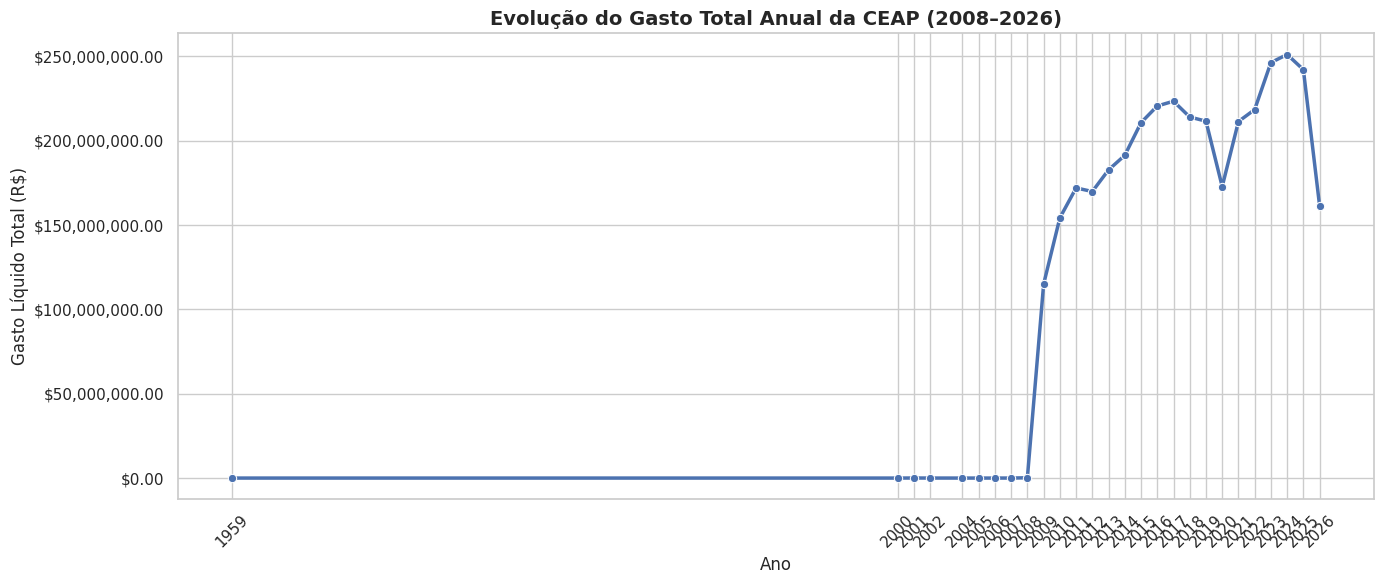

In [ ]:
if 'ano' not in df.columns and 'datemissao' in df.columns:
    df['ano'] = df['datemissao'].dt.year

gasto_anual = df.groupby('ano')['vlrliquido'].sum().reset_index()

plt.figure(figsize=(14, 6))
sns.lineplot(data=gasto_anual, x='ano', y='vlrliquido', marker='o', color='b', linewidth=2.5)
plt.title('Evolução do Gasto Total Anual da CEAP (2008–2026)', fontsize=14, fontweight='bold')
plt.xlabel('Ano', fontsize=12)
plt.ylabel('Gasto Líquido Total (R$)', fontsize=12)
plt.xticks(gasto_anual['ano'].unique(), rotation=45)
plt.gca().yaxis.set_major_formatter('${x:,.2f}')
plt.tight_layout()
plt.show()

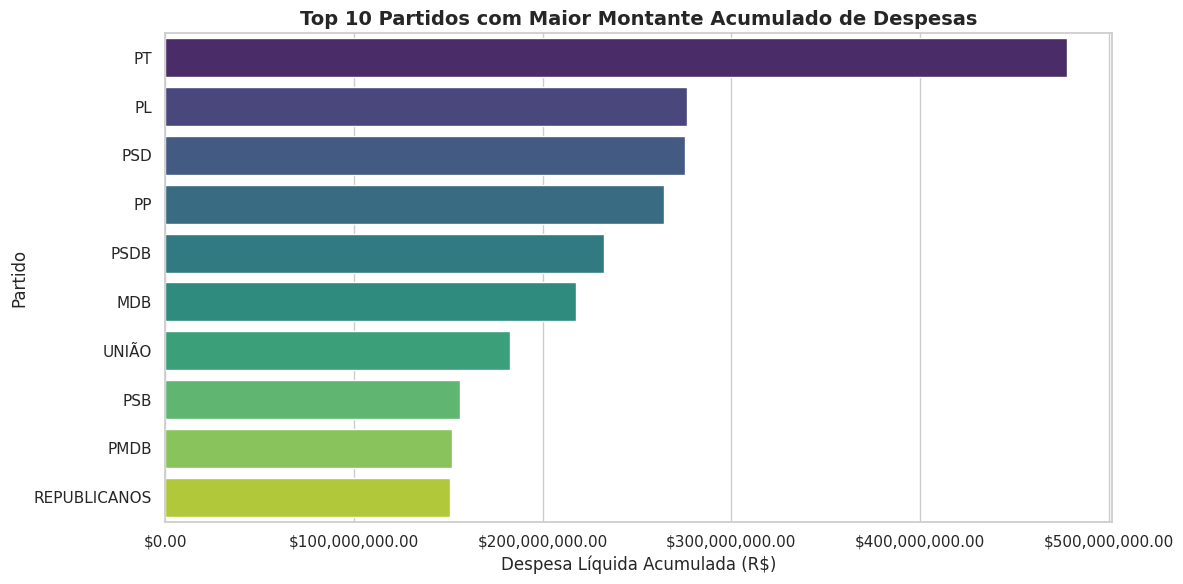

In [ ]:
top_partidos = df.groupby('sgpartido')['vlrliquido'].sum().nlargest(10).reset_index()

plt.figure(figsize=(12, 6))
sns.barplot(data=top_partidos, x='vlrliquido', y='sgpartido', palette='viridis', hue='sgpartido', legend=False)
plt.title('Top 10 Partidos com Maior Montante Acumulado de Despesas', fontsize=14, fontweight='bold')
plt.xlabel('Despesa Líquida Acumulada (R$)', fontsize=12)
plt.ylabel('Partido', fontsize=12)
plt.gca().xaxis.set_major_formatter('${x:,.2f}')
plt.tight_layout()
plt.show()

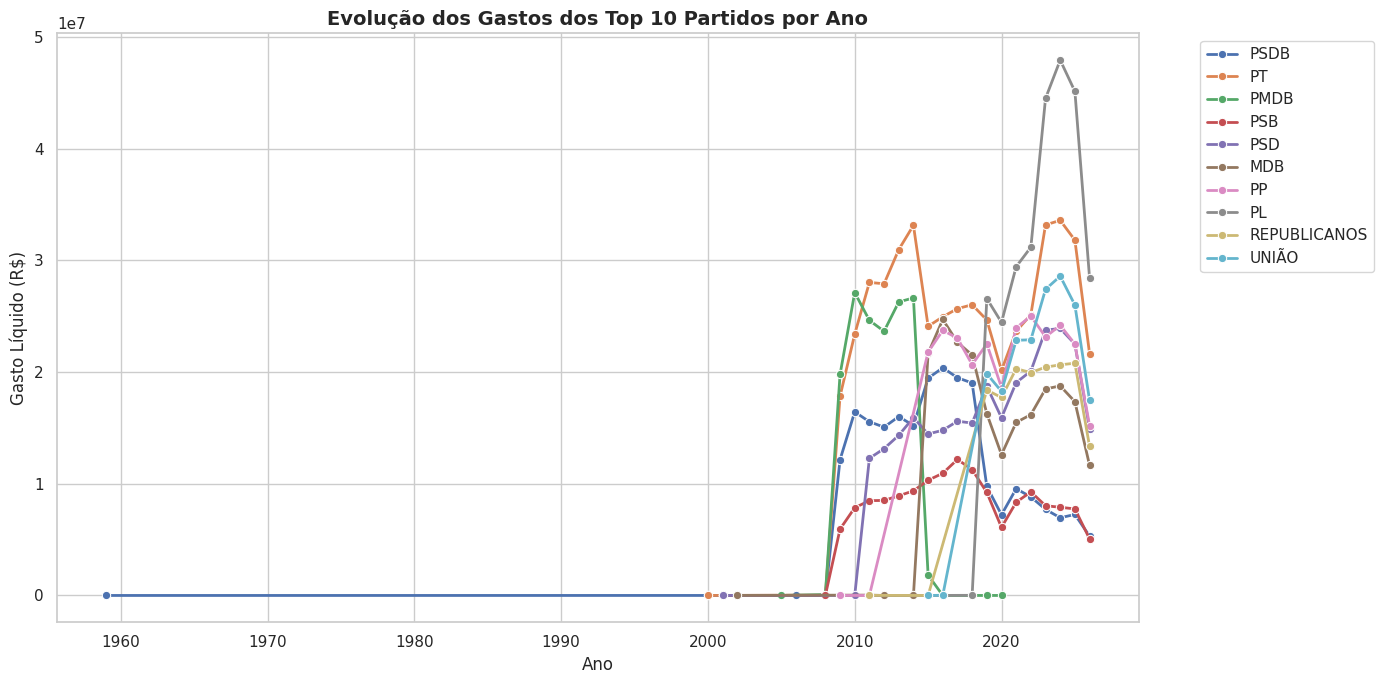

In [ ]:
top_10_list = df.groupby('sgpartido')['vlrliquido'].sum().nlargest(10).index
df_top10_ano = df[df['sgpartido'].isin(top_10_list)].groupby(['ano', 'sgpartido'])['vlrliquido'].sum().reset_index()

plt.figure(figsize=(14, 7))
sns.lineplot(data=df_top10_ano, x='ano', y='vlrliquido', hue='sgpartido', marker='o', linewidth=2)
plt.title('Evolução dos Gastos dos Top 10 Partidos por Ano', fontsize=14, fontweight='bold')
plt.xlabel('Ano', fontsize=12)
plt.ylabel('Gasto Líquido (R$)', fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

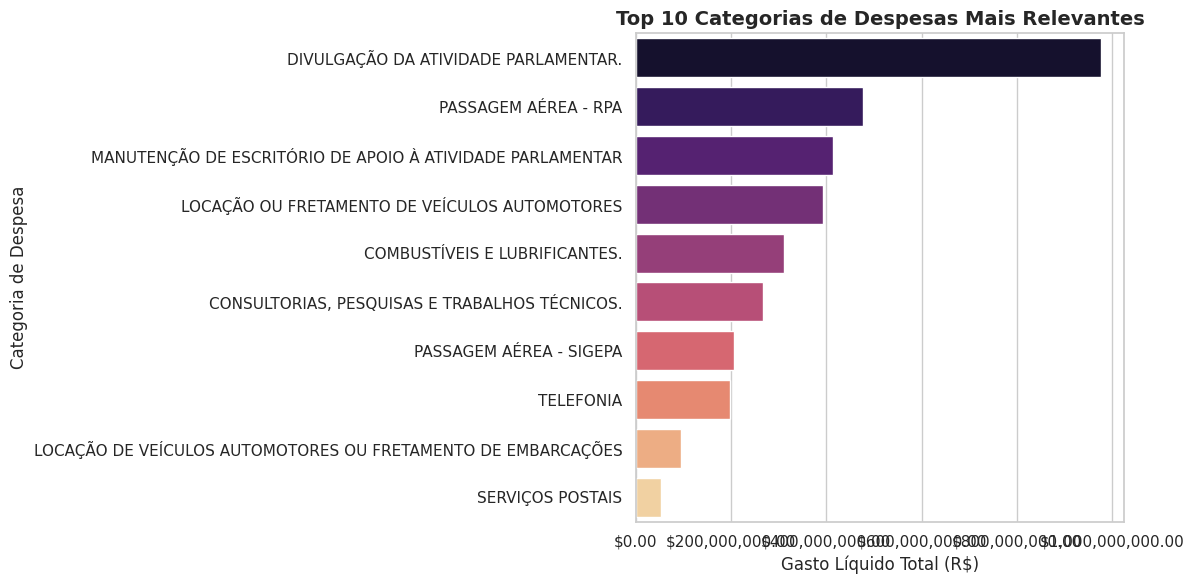

In [ ]:
top_categorias = df.groupby('txtdescricao')['vlrliquido'].sum().nlargest(10).reset_index()

plt.figure(figsize=(12, 6))
sns.barplot(data=top_categorias, x='vlrliquido', y='txtdescricao', palette='magma', hue='txtdescricao', legend=False)
plt.title('Top 10 Categorias de Despesas Mais Relevantes', fontsize=14, fontweight='bold')
plt.xlabel('Gasto Líquido Total (R$)', fontsize=12)
plt.ylabel('Categoria de Despesa', fontsize=12)
plt.gca().xaxis.set_major_formatter('${x:,.2f}')
plt.tight_layout()
plt.show()

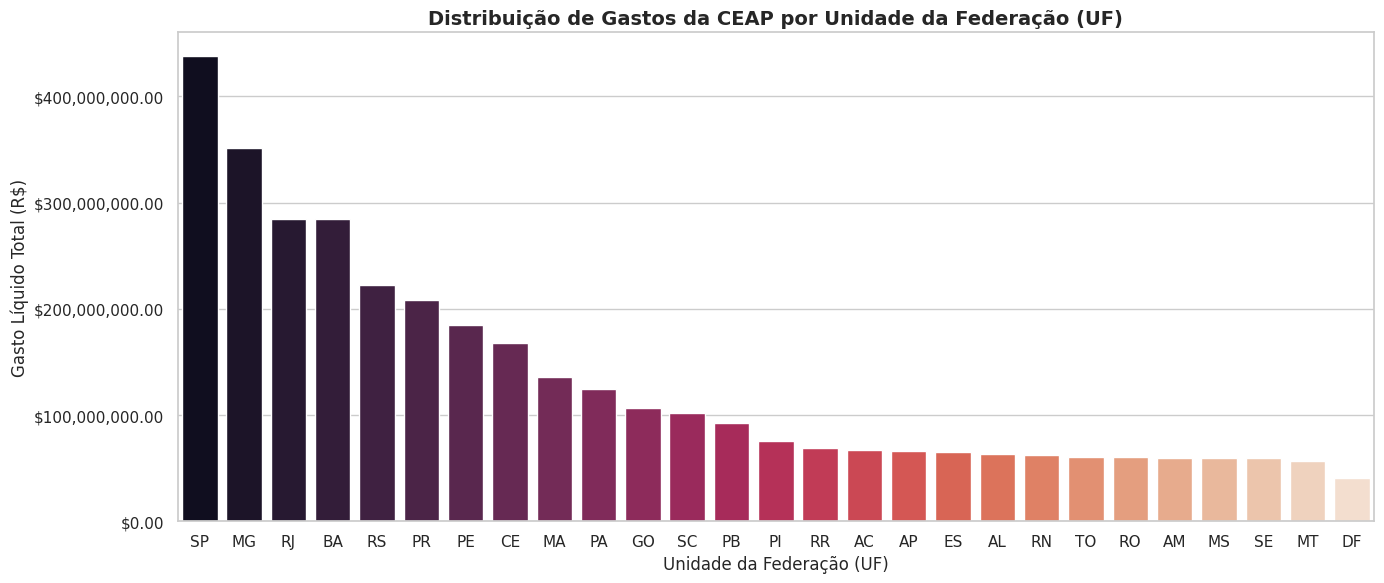

In [ ]:
gasto_uf = df.groupby('sguf')['vlrliquido'].sum().reset_index().sort_values(by='vlrliquido', ascending=False)

plt.figure(figsize=(14, 6))
sns.barplot(data=gasto_uf, x='sguf', y='vlrliquido', palette='rocket', hue='sguf', legend=False)
plt.title('Distribuição de Gastos da CEAP por Unidade da Federação (UF)', fontsize=14, fontweight='bold')
plt.xlabel('Unidade da Federação (UF)', fontsize=12)
plt.ylabel('Gasto Líquido Total (R$)', fontsize=12)
plt.gca().yaxis.set_major_formatter('${x:,.2f}')
plt.tight_layout()
plt.show()

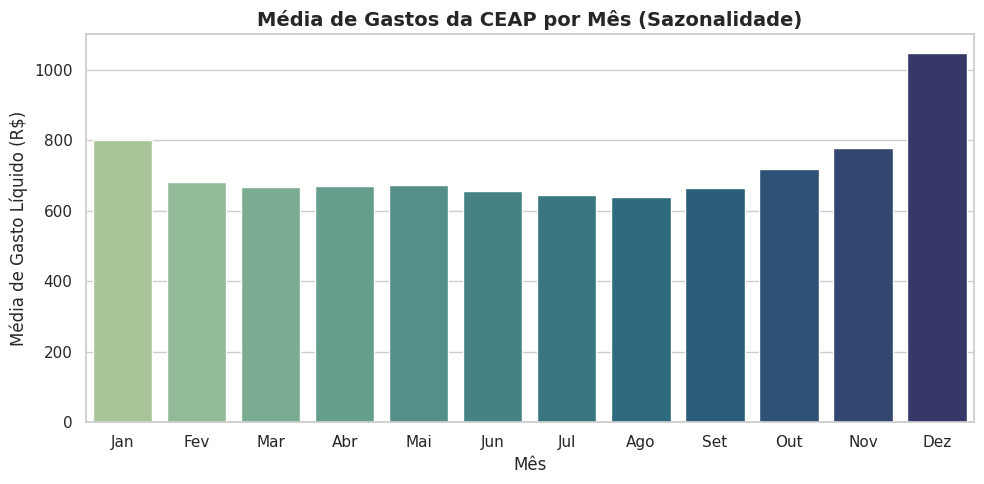

In [ ]:
if 'datemissao' in df.columns:
    df['mes'] = df['datemissao'].dt.month
    gasto_mensal = df.groupby('mes')['vlrliquido'].mean().reset_index()

    plt.figure(figsize=(10, 5))
    sns.barplot(data=gasto_mensal, x='mes', y='vlrliquido', palette='crest', hue='mes', legend=False)
    plt.title('Média de Gastos da CEAP por Mês (Sazonalidade)', fontsize=14, fontweight='bold')
    plt.xlabel('Mês', fontsize=12)
    plt.ylabel('Média de Gasto Líquido (R$)', fontsize=12)
    plt.xticks(ticks=range(12), labels=['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez'])
    plt.tight_layout()
    plt.show()

# 📑 Dossiê de Resolução de Problemas e Análise Crítica — CEAP

Este documento consolida o **Dossiê Técnico de Resolução de Problemas** referente ao pipeline de engenharia de dados (Etapa 2) e a **Análise Crítica** dos insights gerados na exploração visual (Etapa 3) da Cota para Exercício da Atividade Parlamentar (CEAP).

---

## 🛠️ Dossiê de Resolução de Problemas (Etapa 2)

### 1. Diagnóstico Técnico do Erro
Durante a execução do pipeline de ETL iterativo na série histórica de 2008 a 2026, o processamento de determinados arquivos CSV apresentou falhas críticas de leitura, manifestando-se de duas formas principais:
* **Desalinhamento de Campos:** Linhas corrompidas ou quebras de linha inesperadas dentro de colunas de texto livre (como descrições de fornecedores e detalhamento de despesas).
* **Incompatibilidade de Delimitadores e Encodings:** Variação estrutural entre os anos mais antigos e recentes, alternando o caractere separador entre ponto-e-vírgula (`;`) e vírgula (`,`), bem como divergências de codificação (`utf-8` e `latin-1`).

### 2. Investigação da Causa Raiz
A análise linha a linha dos arquivos brutos revelou que as bases mais antigas (em especial o período de 2008 a 2012) continham campos de texto contendo aspas não escapadas e quebras de linha nativas que não seguiam o padrão RFC 4180 de forma estrita. Quando o interpretador padrão lia o arquivo, ele interpretava erroneamente a quebra de linha interna como o fim de um registro, quebrando o esquema tabular e gerando deslocamento de colunas nas iterações de `pandas.read_csv`.

### 3. Solução Técnica Implementada
Para contornar as anomalias sem perder registros valiosos da base pública, a rotina de ingestão foi aprimorada com as seguintes estratégias defensivas:
* **Tratamento de Linhas Inválidas:** Inclusão do parâmetro `on_bad_lines='skip'` para descartar isoladamente registros estruturalmente corrompidos sem interromper o fluxo do pipeline.
* **Detecção Dinâmica de Delimitador e Encoding:** Implementação de um bloco `try-except` com fallback automático de separadores (`sep=';'` e `sep=','`) e codificações (`utf-8` e `latin-1`).
* **Padronização e Alinhamento de Schema:** Criação de um algoritmo genérico que captura as colunas do ano de referência mais recente (`2026`) e assegura que bases de anos passados sejam rigidamente alinhadas, preenchendo colunas ausentes com valores nulos (`NaN`) antes da consolidação final e persistência otimizada no formato colunar **Parquet**.

---

## 📈 Análise Crítica dos Resultados (Etapa 3)

### 1. Evolução de Custos (Gasto Total Anual)
* **Observação:** O gráfico de linha demonstra oscilações consistentes ao longo dos anos, com patamares mais elevados em períodos específicos associados a ciclos de intensa atividade legislativa e reajustes inflacionários acumulados.
* **Hipótese:** O comportamento reflete tanto a variação nos custos operacionais de manutenção de gabinetes e passagens aéreas quanto o rigor de controle de transparência implementado em determinados anos, que impactou a dinâmica de emissão de bilhetes e ressarcimentos.

### 2. Ranking Partidário (Montante Acumulado)
* **Observação:** Os dez partidos com maior montante acumulado de despesas na série histórica coincidem diretamente com as legendas de maior representatividade numérica (bancadas mais numerosas) na Câmara dos Deputados.
* **Hipótese:** O volume financeiro gasto é proporcional ao tamanho do partido, visto que a distribuição de cotas e verbas de gabinete escala em função do número de parlamentares vinculados a cada legenda.

### 3. Ranking Partidário por Ano
* **Observação:** A visualização longitudinal por ano evidencia flutuações na liderança dos gastos que acompanham as janelas partidárias, fusões e a renovação das bancadas decorrente das eleições gerais quadrienais.
* **Hipótese:** Partidos que sofrem perdas expressivas de cadeiras em eleições municipais ou federais apresentam quedas abruptas de despesas consolidadas nos anos subsequentes, reconfigurando o mapa de consumo da cota parlamentar.

### 4. Distribuição das Despesas por Categoria
* **Observação:** Rubricas voltadas à **Divulgação da Atividade Parlamentar** (comunicação, impulsionamento e publicidade) e à **Emissão de Passagens Aéreas** concentram de forma disparada a maior fatia financeira dos recursos despendidos.
* **Hipótese:** A comunicação institucional com os eleitores e a mobilidade constante entre a base eleitoral nos estados e o Congresso Nacional em Brasília representam os pilares operenciais mais custosos para o exercício do mandato.

### 5. Concentração por Estado (UF)
* **Observação:** Unidades da Federação com maiores colégios eleitorais e localizadas geograficamente mais distantes do Distrito Federal (como estados das regiões Norte e Nordeste) lideram o ranking de consumo de recursos.
* **Hipótese:** A distância física encarece significativamente os deslocamentos aéreos semanais dos parlamentares, além de exigir uma estrutura de escritórios de apoio descentralizados mais robusta nos estados de origem.

### 6. Sazonalidade Mensal
* **Observação:** O gráfico de sazonalidade aponta quedas expressivas e previsíveis nos meses de recesso parlamentar (com destaque para janeiro e julho), contrapondo-se a picos de alta intensidade de despesas nos meses de pleno funcionamento legislativo.
* **Hipótese:** A dinâmica dos gastos é estritamente correlacionada ao calendário político institucional; sem votações e com parlamentares em atuação nas bases locais, as despesas operacionais em Brasília sofração retração temporária.

# 🤖 For Github Docs

## 📈 Critical Analysis of Visual Insights

### Cost Evolution (Total Annual Expenditure)

- **Observation:** The annual trend line reveals consistent fluctuations over the years, marked by higher peaks during periods of intense legislative activity and accumulated inflationary adjustments.
- **Hypothesis:** Spending variations reflect both rising operational costs (office maintenance and airfare) and stricter auditing/transparency rules introduced over the years, which altered ticket issuance and reimbursement patterns.

### Party Ranking (Accumulated Amount)

- **Observation:** The top ten political parties with the highest cumulative expenses directly correspond to the parties with the largest numerical representation (largest caucuses) in the Chamber of Deputies.
- **Hypothesis:** Total expenditure scales proportionally with party size, as parliamentary quotas and office allowances are allocated per elected representative.

### Party Ranking by Year

- **Observation:** Longitudinal tracking highlights shifts in spending leadership that mirror party-switching windows (_janelas partidárias_), party mergers, and caucus turnover following quadrennial general elections.
- **Hypothesis:** Parties that lose a significant number of seats in general elections experience sharp drops in consolidated spending in subsequent years, reshaping the overall distribution of parliamentary funds.

### Expense Distribution by Category

- **Observation:** Categories dedicated to **Publicizing Parliamentary Activity** (communication, media production, and advertising) and **Airfare Issuance** overwhelmingly account for the largest share of expended resources.
- **Hypothesis:** Institutional communication with constituents and constant weekly travel between home-state electoral districts and the National Congress in Brasília represent the costliest operational pillars of a parliamentary mandate.

### Concentration by State (UF)

- **Observation:** Federative Units with larger electorates and greater geographic distance from the Federal District (particularly states in the North and Northeast regions) lead the resource consumption ranking.
- **Hypothesis:** Greater physical distance significantly increases the cost of weekly commercial flights for parliamentarians, alongside the need to maintain decentralized regional support offices in their home states.

### Monthly Seasonality

- **Observation:** Monthly averages reveal sharp, predictable drops during parliamentary recess periods (notably January and July), contrasting with spending peaks during months of full legislative sessions.
- **Hypothesis:** Resource consumption is tightly coupled with the institutional political calendar; when floor votes pause and representatives focus on local district work, operational expenses in Brasília temporarily contract.
